In [1]:
import pandas as pd
import matplotlib.pyplot as plt

r = pd.read_csv("../modelos/knn/resumen.csv")
r["modelo"] = r["run_name"].str.replace("p1_", "", regex=False)
versiones = r[r["modelo"] != "referencia_puntaje"]
print(r.loc[1, ["periodo_entrenamiento", "periodo_prueba", "regla_prueba"]].to_dict())
print(r.loc[0, ["n_prueba", "positivos_prueba", "tasa_observada"]].to_dict())

{'periodo_entrenamiento': '2022Q1-2023Q4', 'periodo_prueba': '2024Q1-2024Q4', 'regla_prueba': 'todos los créditos'}
{'n_prueba': 1044262.0, 'positivos_prueba': 5169.0, 'tasa_observada': 0.004949907207195129}


## Desempeño en la prueba

In [2]:
columnas = ["modelo", "k", "auc_roc", "auc_pr", "captura_decil", "precision_decil", "lift_decil", "prob_media", "tasa_observada"]
r[columnas].set_index("modelo").round(5)

,k,auc_roc,auc_pr,captura_decil,precision_decil,lift_decil,prob_media,tasa_observada
modelo,,,,,,,,
referencia_puntaje,NaN,0.77556,0.01828,0.41207,0.02040,4.12069,NaN,0.00495
v1_base,200.0,0.82243,0.02444,0.46856,0.02319,4.68559,0.00518,0.00495
v2_pesos_distancia,200.0,0.82274,0.02505,0.47050,0.02329,4.70494,0.00519,0.00495
v3_proporcion_20,200.0,0.81854,0.02436,0.46605,0.02307,4.66044,0.00519,0.00495
v4_con_estado,200.0,0.82399,0.02516,0.47146,0.02334,4.71461,0.00524,0.00495
v5_formulario,200.0,0.80431,0.02151,0.44070,0.02181,4.40701,0.00542,0.00495


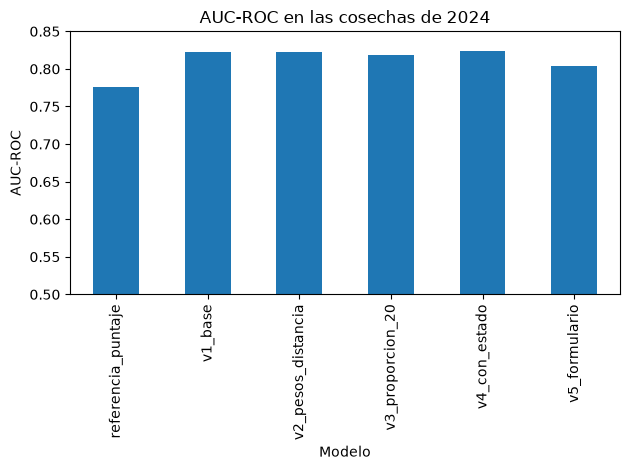

In [3]:
ax = r.plot.bar(x="modelo", y="auc_roc", legend=False, title="AUC-ROC en las cosechas de 2024")
ax.set_xlabel("Modelo")
ax.set_ylabel("AUC-ROC")
ax.set_ylim(0.5, 0.85)
plt.tight_layout()
plt.show()

Las cinco versiones superan al puntaje solo en AUC-ROC, AUC-PR y captura del decil superior. v1, v2 y v4 quedan prácticamente empatadas y v5, que usa solo las variables del formulario de la maqueta, queda por debajo de las demás, así que las variables de la solicitud que el formulario no pide aportan al modelo. La probabilidad media corregida queda cerca de la tasa observada: la corrección por el submuestreo devuelve las probabilidades a la escala real.

## Elección de k

In [4]:
auc_k = versiones.set_index("modelo")[["auc_validacion_k25", "auc_validacion_k50", "auc_validacion_k100", "auc_validacion_k200"]]
auc_k.columns = [25, 50, 100, 200]
print((auc_k[200] - auc_k[100]).round(4))
auc_k.round(4)

modelo
v1_base               0.0029
v2_pesos_distancia    0.0028
v3_proporcion_20      0.0077
v4_con_estado         0.0026
v5_formulario         0.0066
dtype: float64


,25,50,100,200
modelo,,,,
v1_base,0.7744,0.7923,0.7992,0.8021
v2_pesos_distancia,0.7747,0.7924,0.8002,0.8030
v3_proporcion_20,0.7499,0.7764,0.7923,0.8001
v4_con_estado,0.7707,0.7930,0.7993,0.8019
v5_formulario,0.7379,0.7593,0.7704,0.7770


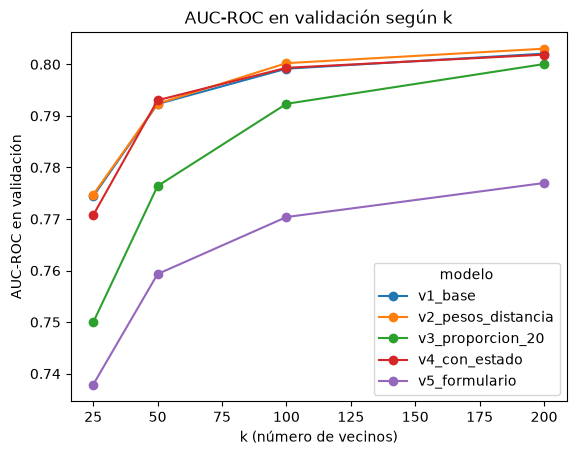

In [5]:
ax = auc_k.T.plot(marker="o", title="AUC-ROC en validación según k")
ax.set_xlabel("k (número de vecinos)")
ax.set_ylabel("AUC-ROC en validación")
plt.show()

El AUC en validación sube con k en todas las versiones, cada vez menos. En todas se eligió k = 200, el máximo de la grilla; entre 100 y 200 la mejora de v1, v2 y v4 es de unas milésimas, así que un k mayor aportaría poco.

## Costo de cómputo

In [6]:
costo = versiones.set_index("modelo")[["n_entrenamiento", "positivos_entrenamiento", "n_columnas_codificadas", "tiempo_prediccion_s", "tamano_modelo_mb"]].copy()
costo["tiempo_prediccion_min"] = costo.pop("tiempo_prediccion_s") / 60
costo.round(1)

,n_entrenamiento,positivos_entrenamiento,n_columnas_codificadas,tamano_modelo_mb,tiempo_prediccion_min
modelo,,,,,
v1_base,164901.0,14991.0,29.0,3.1,18.2
v2_pesos_distancia,164901.0,14991.0,29.0,3.1,18.5
v3_proporcion_20,299985.0,14285.0,29.0,5.6,30.6
v4_con_estado,164901.0,14991.0,83.0,4.8,25.0
v5_formulario,164901.0,14991.0,68.0,3.6,23.7


El costo está en la predicción, que compara cada crédito con todo el entrenamiento. v4 agrega columnas por el estado y v3 agrega filas por la proporción 1 a 20; ambas tardan más que v1 sin una mejora que lo compense.

## Conclusiones

- Se selecciona v2: la de mayor AUC-ROC entre las versiones sin el estado, con el mismo costo que la versión base.
- El estado no se incluye: su mejora es marginal y alarga la predicción.
- El formulario de la Evaluación debería pedir también las variables de la solicitud que hoy no incluye, porque sin ellas el modelo pierde capacidad de ordenar el riesgo.